In [1]:
from pathlib import Path
import yaml

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent

# 0. Загружаем и смотрим структуру

In [2]:
config_path = project_root / "config.yaml"
with config_path.open(encoding="utf-8") as file:
    config = yaml.safe_load(file)

train = pd.read_csv(project_root / config["data"]["train_path"])
test = pd.read_csv(project_root / config["data"]["test_path"])

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [4]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1459 non-null   int64  
 1   MSSubClass     1459 non-null   int64  
 2   MSZoning       1455 non-null   str    
 3   LotFrontage    1232 non-null   float64
 4   LotArea        1459 non-null   int64  
 5   Street         1459 non-null   str    
 6   Alley          107 non-null    str    
 7   LotShape       1459 non-null   str    
 8   LandContour    1459 non-null   str    
 9   Utilities      1457 non-null   str    
 10  LotConfig      1459 non-null   str    
 11  LandSlope      1459 non-null   str    
 12  Neighborhood   1459 non-null   str    
 13  Condition1     1459 non-null   str    
 14  Condition2     1459 non-null   str    
 15  BldgType       1459 non-null   str    
 16  HouseStyle     1459 non-null   str    
 17  OverallQual    1459 non-null   int64  
 18  OverallCond    1459

1460 объектов в тренировочной выборке, столько же в тестовой выборке. Общее число признаков 81: числовых 36, категориальных 43 + Id and SalePrice.

# 1. Исследуем датасет на пропуски

Text(0.5, 0, '% пропусков')

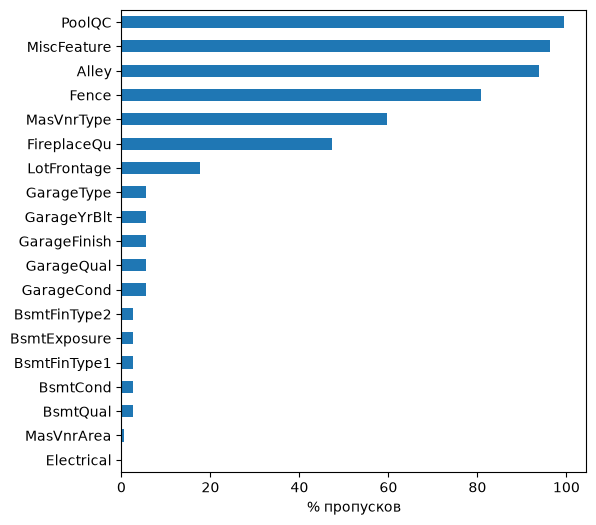

In [5]:
missing = train.isnull().mean() * 100          
missing = missing[missing > 0].sort_values()
missing.plot.barh(figsize=(6, 6))              
plt.xlabel('% пропусков')

Пропуски есть в 19 признаках, причём у 5 из них (PoolQC, MiscFeature, Alley, Fence, MasVnrType) пропущено больше половины значений.

Согласно описанию датасета, значение NA в таких признаках означает, что у дома нет соответствующего объекта: бассейна, забора, камина, подвала, гаража, облицовки и т.д. 

У MasVnrType pandas при чтении распознал значение «None» (нет облицовки) как пропуск.

Настоящая потеря данных есть только в трёх признаках:

LotFrontage — ширина участка вдоль улицы, она есть у любого дома;
MasVnrArea (8 строк);
Electrical (1 строка).


Что можно делать при предобработке:

- в категориальных признаках, где NA означает «нет объекта», заменим пропуски на значение “None”

- LotFrontage заполним медианой

- MasVnrArea заполним нулём (нет облицовки — нет площади)

- Electrical заполним самым частым значением

# 2. Распределение таргета

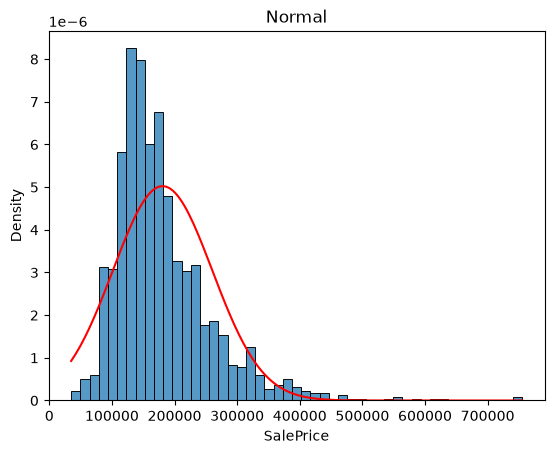

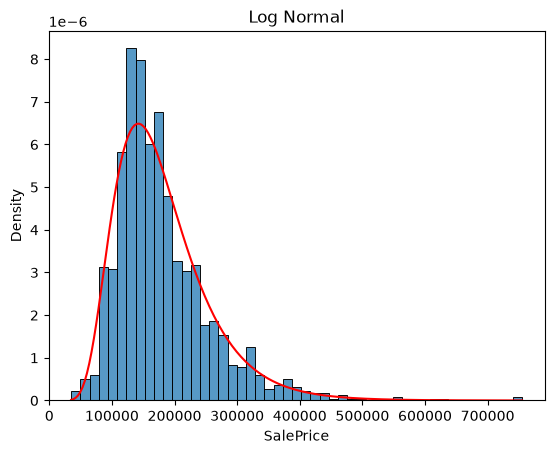

In [6]:
y = train['SalePrice']

def plot_fit(y, dist, title):
    plt.figure()
    plt.title(title)
    sns.histplot(y, stat='density')
    x = np.linspace(y.min(), y.max(), 200)
    params = dist.fit(y)
    plt.plot(x, dist.pdf(x, *params), color='red')

plot_fit(y, stats.norm, 'Normal')
plot_fit(y, stats.lognorm, 'Log Normal')

Распределение цены не нормальное: оно скошено вправо. Большинство домов стоит 100–250 тыс., но есть длинный хвост дорогих домов.

Логнормальное распределение (красная кривая) хорошо описывает данные, то есть логарифм цены распределён примерно нормально. Поэтому при обучении модели будем предсказывать log(SalePrice), а не саму цену.

# 3. Связь числовых признаков с ценой

<Axes: >

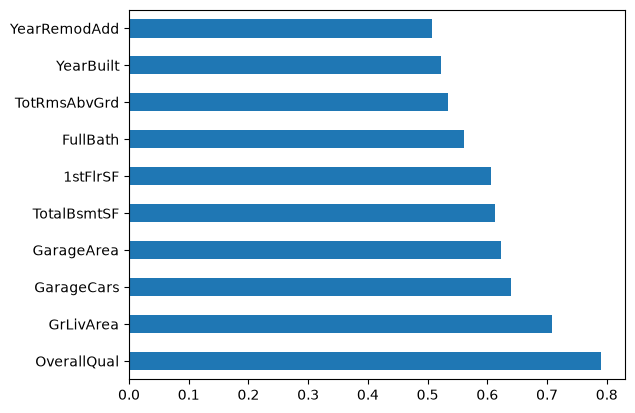

In [7]:
corr = train.select_dtypes('number').corr()['SalePrice'].sort_values(ascending=False)
corr[1:11].plot.barh()

Сильнее всего с ценой связаны:
- общее качество дома (OverallQual)
- жилая площадь над землёй (GrLivArea)
- вместимость гаража (GarageCars)
- площадь гаража (GarageArea)
- площадь подвала (TotalBsmtSF)
- площадь первого этажа (1stFlrSF)
- число полноценных ванных (FullBath)
- число комнат над землёй (TotRmsAbvGrd)
- год постройки (YearBuilt)
- год ремонта (YearRemodAdd)

Можно заметить, что в топе есть похожие признаки (GarageCars и GarageArea, TotalBsmtSF и 1stFlrSF) — проверим это на шаге 5.

# 4. Исследуем выбросы

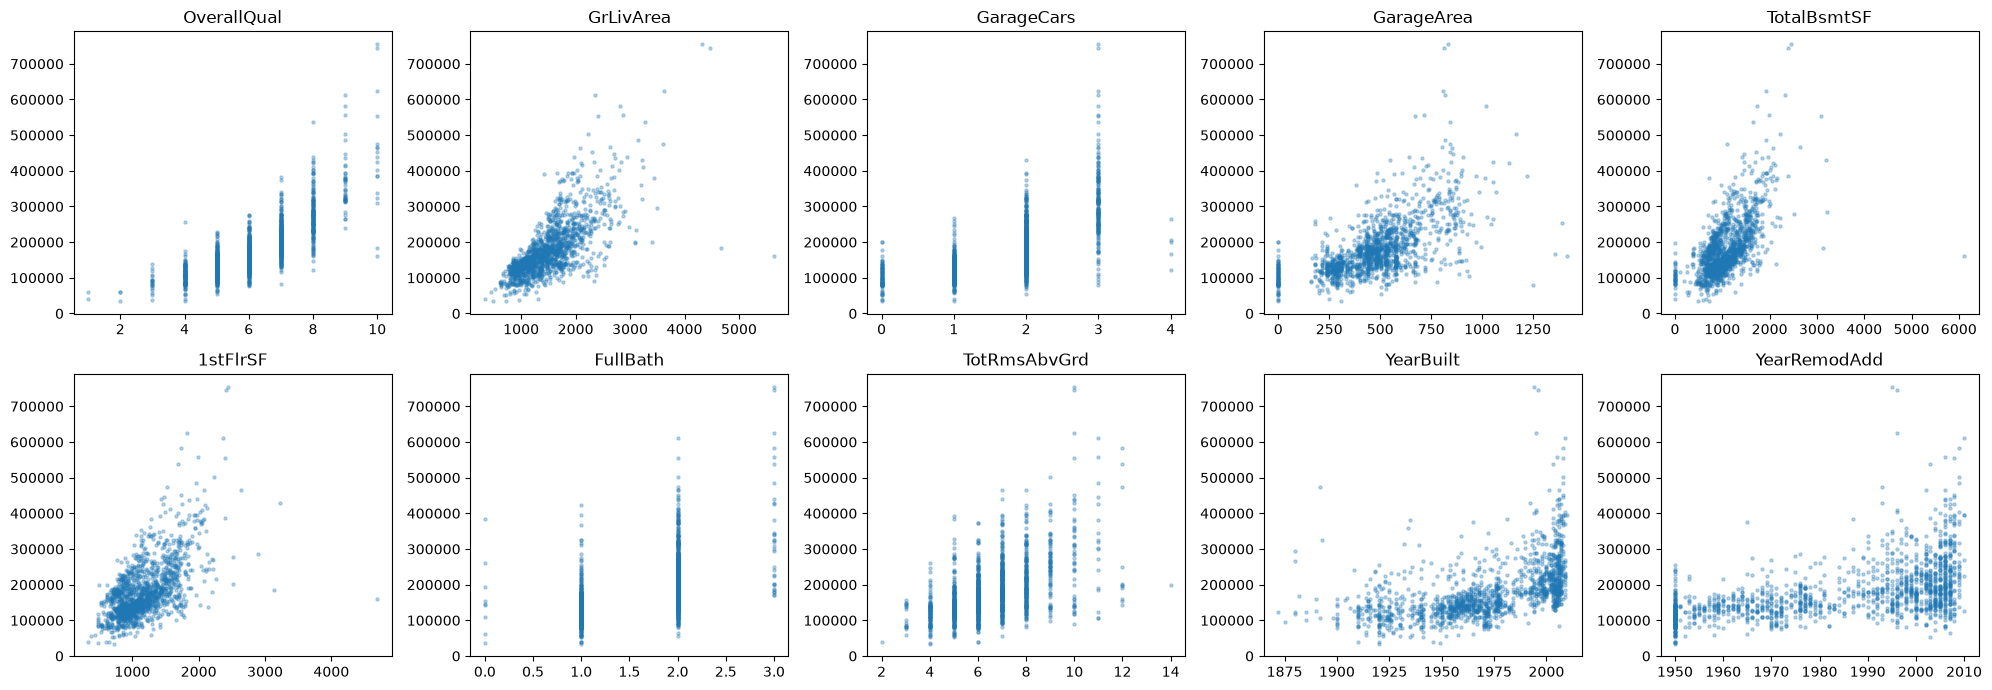

In [8]:
top = corr.index[1:11]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for col, ax in zip(top, axes.flat):
    ax.scatter(train[col], train['SalePrice'], alpha=0.3, s=5)
    ax.set_title(col)
plt.tight_layout()

Все топ-признаки положительно связаны с ценой, но зависимости не всегда линейные: цена растёт с качеством ускоренно, новые дома (после ~2000 года) резко дороже остальных, а гаражи на 4 машины дешевле гаражей на 3. С ростом площади растёт и разброс цен — ещё один аргумент за логарифмирование цены.

На графиках площадей (GrLivArea, TotalBsmtSF, 1stFlrSF) и качества (OverallQual) выделяются 2 дома: огромная площадь и максимальное качество при цене как у среднего дома. Это выбросы, их удалим из обучающей выборки.

In [9]:
train[(train['GrLivArea'] > 4500) & (train['SalePrice'] < 300000)][
    ['GrLivArea', 'TotalBsmtSF', '1stFlrSF', 'OverallQual', 'SalePrice', 'SaleCondition']]

,GrLivArea,TotalBsmtSF,1stFlrSF,OverallQual,SalePrice,SaleCondition
523,4676,3138,3138,10,184750,Partial
1298,5642,6110,4692,10,160000,Partial


SaleCondition у них Partial, значит они на стадии постройки, это объясняет низкую цену

# 5. Исследуем корреляции между топ-фичами

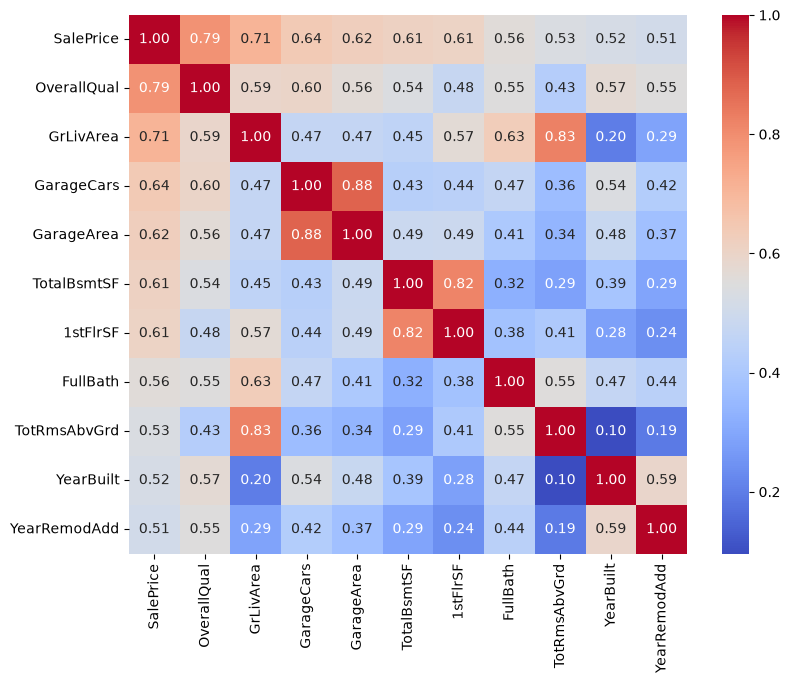

In [10]:
top = corr.index[:11]   # SalePrice + топ-10
plt.figure(figsize=(9, 7))
sns.heatmap(train[top].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

Среди наиболее важных фичей есть сильно коррелирующие между собой пары: 
- GarageCars и GarageArea 0.88
- TotRmsAbvGrd и GrLivArea 0.83
- TotalBsmtSF и 1stFlrSF 0.82

Такая мультиколлинеарность вредна для линейной модели, поэтому в случае линейной модели в каждой паре оставим фичу, которая сильнее коррелирует с ценой:

- GarageCars
- GrLivArea 
- у TotalBsmtSF и 1stFlrSF корреляция с таргетом одинаковая. Можно объединить их в общую площадь TotalSF

# 6. Связь категориальных признаков с ценой



Для каждого категориального признака проверим, различается ли средняя цена домов между его категориями (например, между районами). Для этого используем однофакторный дисперсионный анализ (ANOVA): он даёт p-value — вероятность получить такую разницу случайно, если признак на цену не влияет.

Чтобы сравнивать очень маленькие p-value, на графике откладываем ln(1/p): чем выше столбик, тем сильнее связь признака с ценой. Пунктирная линия — порог значимости p = 0.05, столбики выше неё означают статистически значимую связь.

In [11]:
qualitative = train.select_dtypes('object').columns.tolist()

/var/folders/2_/ftzyn6yx1n7dgtpc8vqp3d4w0000gq/T/ipykernel_53904/894004391.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  qualitative = train.select_dtypes('object').columns.tolist()


/var/folders/2_/ftzyn6yx1n7dgtpc8vqp3d4w0000gq/T/ipykernel_53904/1351624279.py:15: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  a = anova(train.fillna('None'))


Число проверенных признаков: 43


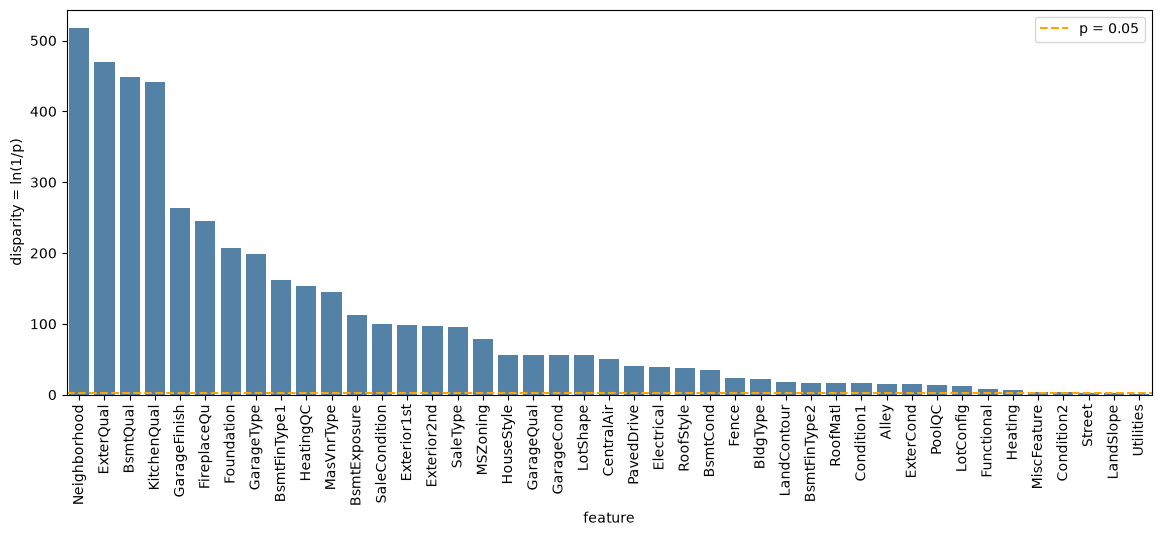

In [12]:
def anova(frame):
    anv = pd.DataFrame()
    anv['feature'] = qualitative
    pvals = []
    for c in qualitative:
        samples = []
        for cls in frame[c].unique():
            s = frame[frame[c] == cls]['SalePrice'].values
            samples.append(s)
        pval = stats.f_oneway(*samples)[1]
        pvals.append(pval)
    anv['pval'] = pvals
    return anv.sort_values('pval')

a = anova(train.fillna('None'))
a['disparity'] = np.log(1. / a['pval'].values)

n = len(a)   
print(f"Число проверенных признаков: {n}")

plt.figure(figsize=(14, 5))
sns.barplot(data=a, x='feature', y='disparity', color='steelblue')
plt.axhline(np.log(1 / 0.05), color='orange', linestyle='--', label='p = 0.05')
plt.xticks(rotation=90)
plt.ylabel('disparity = ln(1/p)')
plt.legend()
plt.show()

**Вывод**

Почти все категориальные признаки значимо связаны с ценой. Сильнее всего — район (Neighborhood) и признаки качества: фасада (ExterQual), подвала (BsmtQual) и кухни (KitchenQual). Не связаны с ценой только почти константные признаки в конце списка (MiscFeature, Condition2, Street, LandSlope, Utilities), их можно удалить.

# Итоги EDA

1. Целевая переменная. Распределение SalePrice скошено вправо и хорошо описывается логнормальным распределением. Будем предсказывать log(SalePrice).

2. Пропуски. Большинство пропусков означает отсутствие объекта (нет гаража, подвала, бассейна и т.д.). Настоящие пропуски есть только у LotFrontage, MasVnrArea и Electrical.

3. Важные признаки. Сильнее всего с ценой связаны общее качество дома (OverallQual), жилая площадь (GrLivArea) и район (Neighborhood), а также качество фасада, подвала и кухни.

4. Выбросы. Найдены 2 недостроенных дома (SaleCondition = Partial) с огромной площадью и низкой ценой. Удалить из обучающей выборки.

5. Мультиколлинеарность. Признаки GarageArea, TotRmsAbvGrd и 1stFlrSF дублируют GarageCars, GrLivArea и TotalBsmtSF соответственно. Оставим GarageCars, GrLivArea; TotalBsmtSF и 1stFlrSF объединим в TotalSF.

6. Бесполезные признаки. Почти константные признаки (Utilities, Street, Condition2) не связаны с ценой, их можно удалить.